# 29. GraphRAG

Extract a knowledge graph from the documents and answer questions by walking it.

[![X](https://img.shields.io/badge/X-000000?style=for-the-badge&logo=x&logoColor=white)](https://x.com/techwith_ram) [![GitHub](https://img.shields.io/badge/GitHub-181717?style=for-the-badge&logo=github&logoColor=white)](https://github.com/Ramakm) [![LinkedIn](https://img.shields.io/badge/LinkedIn-0A66C2?style=for-the-badge&logo=linkedin&logoColor=white)](https://www.linkedin.com/in/ramakrushnamohapatra/) [![Instagram](https://img.shields.io/badge/Instagram-E4405F?style=for-the-badge&logo=instagram&logoColor=white)](https://instagram.com/techwith.ram) [![Medium](https://img.shields.io/badge/Medium-000000?style=for-the-badge&logo=medium&logoColor=white)](https://medium.com/@techwithram)

## Why this matters

Some questions need **relationships**, not similar text: *'Which tool does the system that uses HNSW rely on?'*. Vector search finds passages that look alike; a knowledge graph stores `subject --relation--> object` triples so you can **traverse** from one entity to another (multi-hop). **GraphRAG** has an LLM extract triples, builds a graph, and answers from the neighbourhood of the question's entities.

## How it works

1. Extract (subject, relation, object) triples from each chunk with the LLM
2. Build a directed multigraph with networkx
3. Extract entities from the question
4. Match them to graph nodes and expand 1-2 hops
5. Turn the neighbourhood edges into facts and generate the answer

```text
 chunk --LLM--> (hnsw, is a, graph index)  (faiss, is a, library) ...
                         \
                          graph  <-- entities in question --> neighbourhood --> facts --> LLM
```

## Prerequisites

Needs a running Ollama server (`ollama serve`) with `llama3.2` pulled, plus the shared helpers in `../common.py`.

**Extra requirements for this notebook:** `pip install networkx`

## Setup

Load the handbook, split it into ~500-character chunks (50 overlap) and index them. Every notebook starts from this same baseline so results are comparable.

In [1]:
import sys
sys.path.insert(0, "..")  # makes common.py importable
from common import *

text = load_text()
chunks = chunk_text(text, size=500, overlap=50)
store = build_store(chunks)
print(f"{len(chunks)} chunks indexed")

W1028 11:05:27.766000 9184 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


19 chunks indexed


In [2]:
import networkx as nx

G = nx.MultiDiGraph()
for i, chunk in enumerate(chunks[:15]):
    for s, r, o in extract_triples(chunk):
        G.add_edge(s, o, relation=r, chunk=i)
print(G.number_of_nodes(), "entities,", G.number_of_edges(), "relations")
list(G.edges(data="relation"))[:8]

122 entities, 93 relations


[('rag', 'model', 'combines'),
 ('rag', 'knowledge', 'supplies'),
 ('rag', 'yes', 'query time'),
 ('model', 'vectors', 'maps'),
 ('model', 'dimensions', 'produces'),
 ('model', 'popular', 'is'),
 ('model', 'reranker', 'uses'),
 ('model', 'ignore', 'can')]

## Query: find entities in the question, then expand their neighbourhood

In [3]:
def graph_context(query, hops=1, max_facts=15):
    entities = llm_json(f"List the key entities in this question as a JSON list of lowercase strings.\n\n{query}") or []
    nodes = [n for n in G.nodes if any(e.lower() in n or n in e.lower() for e in entities)]
    facts = set()
    frontier = set(nodes)
    for _ in range(hops):
        nxt = set()
        for n in frontier:
            for u, v, d in list(G.out_edges(n, data=True)) + list(G.in_edges(n, data=True)):
                facts.add(f"{u} {d['relation']} {v}")
                nxt.update([u, v])
        frontier = nxt
    return nodes, sorted(facts)[:max_facts]

query = "What does HNSW do and which libraries use vector indexes?"
nodes, facts = graph_context(query)
print("matched:", nodes); print("\n".join(facts))
print(answer(query, facts) if facts else "no graph facts matched")

matched: []

no graph facts matched


Graph retrieval shines for multi-hop questions (A relates to B relates to C) that no single chunk answers.

## Look at the graph
Inspect the biggest hubs and a sample of edges - extraction quality decides everything downstream.

In [4]:
import pandas as pd
deg = pd.Series(dict(G.degree())).sort_values(ascending=False)
print("most connected entities:\n", deg.head(8))
print("\nsample edges:")
for u, v, d in list(G.edges(data=True))[:10]:
    print(f"  ({u}) --[{d['relation']}]--> ({v})")

most connected entities:
 model            14
graph             7
evaluation        6
yes               5
hybrid search     5
vector            5
context           4
facts             4
dtype: int64

sample edges:
  (rag) --[combines]--> (model)
  (rag) --[supplies]--> (knowledge)
  (rag) --[query time]--> (yes)
  (model) --[maps]--> (vectors)
  (model) --[produces]--> (dimensions)
  (model) --[is]--> (popular)
  (model) --[uses]--> (reranker)
  (model) --[can]--> (ignore)
  (model) --[ignore]--> (context)
  (model) --[over-generalise]--> (context)


## Visualise it

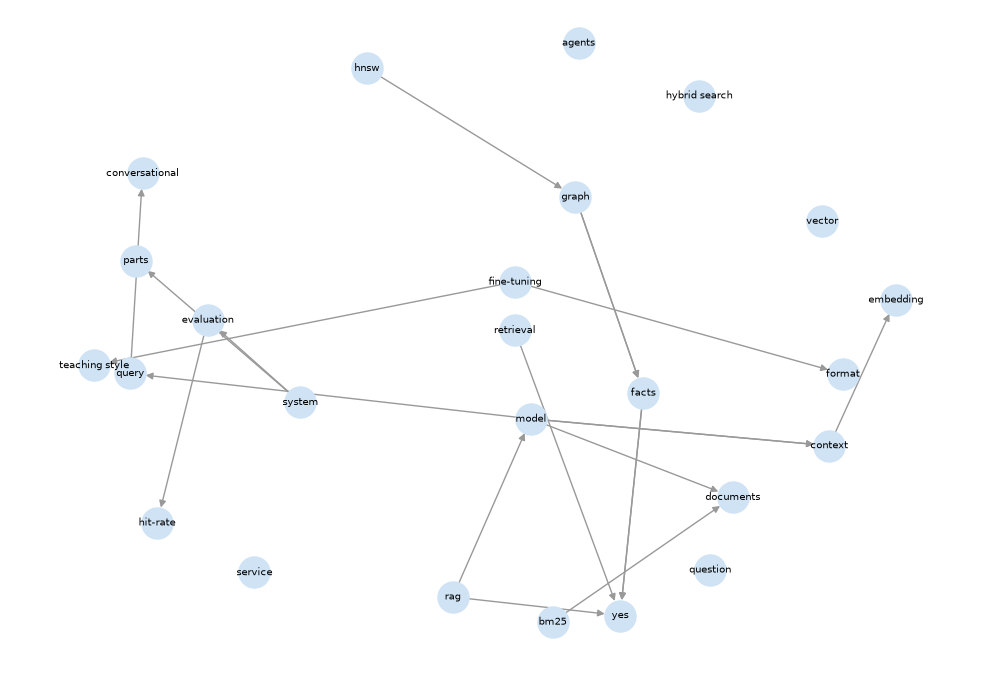

In [5]:
import matplotlib.pyplot as plt
top = set(deg.head(25).index)
sub = G.subgraph(top)
plt.figure(figsize=(10, 7))
pos = nx.spring_layout(sub, seed=3, k=0.9)
nx.draw_networkx(sub, pos, node_size=500, font_size=7, node_color="#cfe3f5", edge_color="#999", arrows=True)
plt.axis("off"); plt.tight_layout(); plt.show()

## Multi-hop: follow a path
Graph traversal can connect two entities even when no single chunk mentions both.

In [6]:
nodes_list = list(G.nodes)
pairs = [(a, b) for a in nodes_list[:15] for b in nodes_list[:15] if a != b and nx.has_path(G.to_undirected(), a, b)]
if pairs:
    a, b = max(pairs, key=lambda p: nx.shortest_path_length(G.to_undirected(), *p))
    path = nx.shortest_path(G.to_undirected(), a, b)
    print("longest short-path found:", " -> ".join(path))

longest short-path found: generation -> retrieval -> yes -> rag -> model -> vectors


## Compare against vector RAG

In [7]:
def graph_rag_answer(q):
    nodes_, facts_ = graph_context(q)
    return answer(q, facts_) if facts_ else "No graph facts matched."

compare_pipelines({"vector RAG": lambda q: rag(q, store, 3)[0], "GraphRAG (facts only)": graph_rag_answer}, n=4)

,keyword_recall,judge_correct,avg_seconds
pipeline,,,
vector RAG,0.79,1.0,0.0
GraphRAG (facts only),0.12,0.0,2.2


## Trade-offs

| Strengths | Weaknesses |
|---|---|
| Multi-hop reasoning | Extraction is expensive and noisy (small LLMs miss or invent triples) |
| Explicit, inspectable structure | Entity names need normalisation (HNSW vs hierarchical navigable small world) |
| Compact context (facts, not paragraphs) | Loses nuance that only exists in prose |

## When to use it

Entity-rich domains (people, organisations, products, genes) and questions that follow relationships. Combine with vector search for coverage.

## Experiments to try

- Normalise entity names with embeddings before adding nodes.
- Send both graph facts and source chunks to the LLM.
- Add edge weights by co-occurrence frequency.

## Key takeaways

- Graph = entities + relations extracted by an LLM.
- Retrieval = neighbourhood expansion.
- Extraction quality is the bottleneck.

---
**Next:** [30. GraphRAG with a Milvus Vector DB](../30_graphrag_with_milvus_vectordb/graphrag_with_milvus_vectordb.ipynb)